# Creation of toy datasets using Scikit-learn

## Classification

## Using *make_*

In [2]:
from sklearn.datasets import make_classification, make_regression, make_blobs, make_moons

In [3]:
# X_clf: A 2D NumPy array of shape (100, 4) containing the input features (independent variables).
# y_clf: A 1D NumPy array of shape (100,) containing the target labels (0 or 1 by default).

X_clf, y_clf = make_classification(
    n_samples=100,      # Total number of data points (rows) to generate.
    n_features=3,       # Total number of features (columns). It equals: informative + redundant + repeated + random noise.
    n_informative=3,    # Number of features that actually carry useful signal to separate the classes.
    n_redundant=0,      # Number of features generated as random linear combinations of the informative features (set to 0 here, so no multicollinearity).
                        # Note: Because n_features=3 and informative+redundant=2, the remaining 1 feature is filled with pure random noise.
    random_state=42,     # Seed for the random number generator. Ensures you get the exact same dataset every time you run the code.
    n_classes=3,            # Configures y_clf to have values: 0, 1, or 2
    n_clusters_per_class=1,
    class_sep=1.1,
)

In [4]:
print("X_clf")
print(X_clf[:5,:])
print("shape", X_clf.shape)
print()

print("y_clf")
print(y_clf[:5])
print("shape", y_clf.shape)

X_clf
[[-0.73653144  0.53905714 -1.38721733]
 [-0.45714951  0.84837919  1.2344456 ]
 [-2.21161929 -0.58086296 -0.41786597]
 [-0.3637195  -1.26719686  1.00058994]
 [ 0.41448008 -0.47386752  1.10076847]]
shape (100, 3)

y_clf
[2 1 0 0 1]
shape (100,)


In [5]:
import matplotlib.pyplot as plt

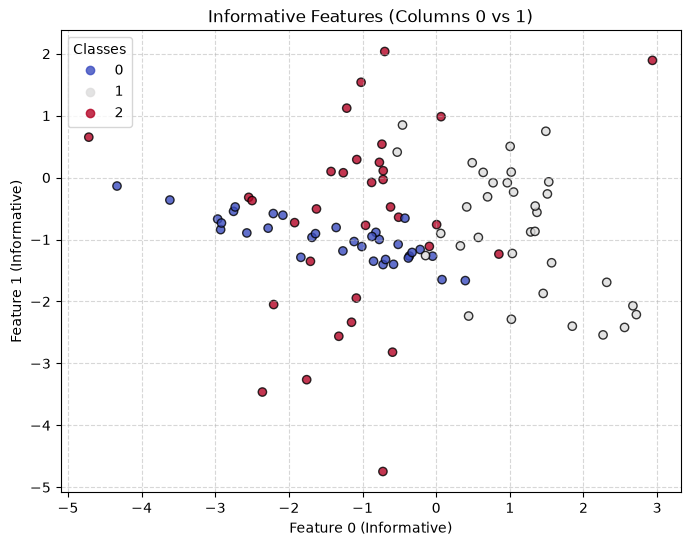

In [6]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_clf[:, 0],          # First informative feature (X-axis)
    X_clf[:, 1],          # Second informative feature (Y-axis)
    c=y_clf,              # Color points by their class label (0 or 1)
    cmap='coolwarm',      # Color scheme (blue vs. red)
    edgecolors='k',       # Black border around dots for readability
    alpha=0.8
)

plt.title("Informative Features (Columns 0 vs 1)")
plt.xlabel("Feature 0 (Informative)")
plt.ylabel("Feature 1 (Informative)")
plt.legend(*scatter.legend_elements(), title="Classes")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

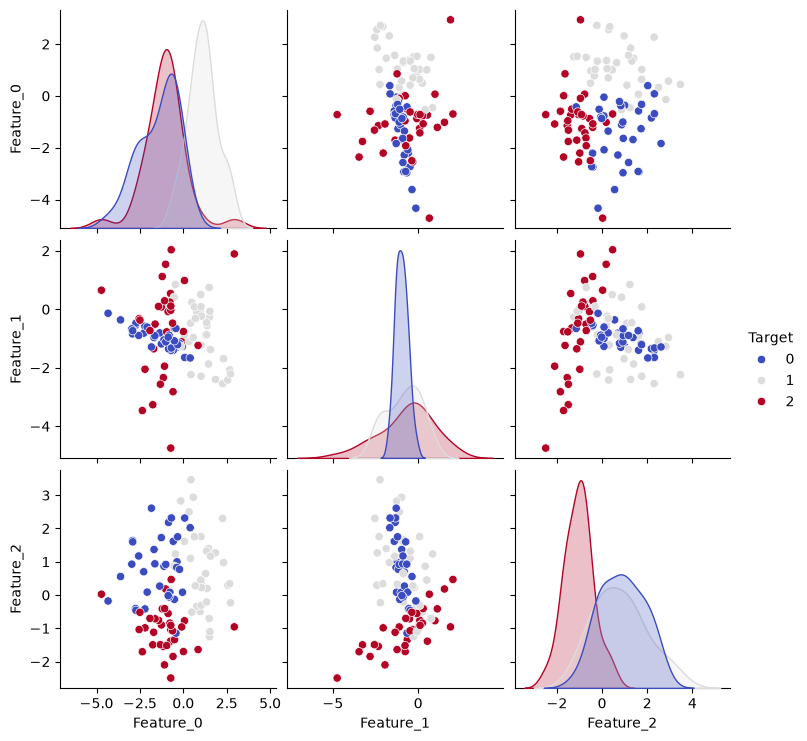

In [7]:
import pandas as pd
import seaborn as sns

# Convert to DataFrame for easy plotting
df = pd.DataFrame(X_clf, columns=[f"Feature_{i}" for i in range(3)])
df["Target"] = y_clf

# Creates a 4x4 grid comparing every feature pair
sns.pairplot(df, hue="Target", palette="coolwarm", diag_kind="kde")
plt.show()

In [8]:
df.to_csv("./dbs/classification_toy_dataset.csv", index=False)

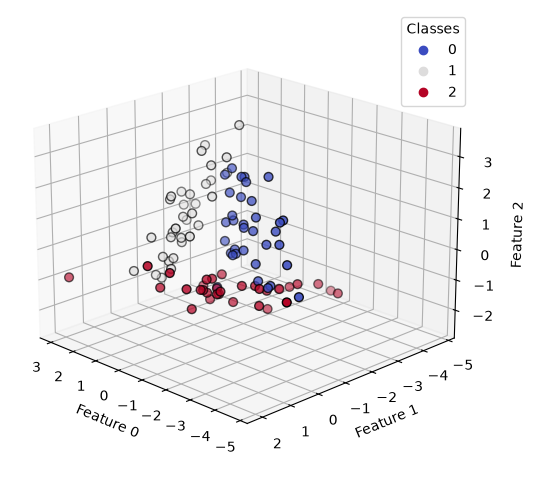

In [9]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(
    X_clf[:, 0], X_clf[:, 1], X_clf[:, 2],
    c=y_clf, cmap='coolwarm', edgecolors='k', s=40
)
ax.set_xlabel("Feature 0")
ax.set_ylabel("Feature 1")
ax.set_zlabel("Feature 2")

ax.view_init(elev=20, azim=135)  # elev: up/down angle, azim: left/right rotation

plt.legend(*scatter.legend_elements(), title="Classes")
plt.show()

In [10]:
import plotly.express as px

# Map each target class (as a string) to a specific color
custom_colors = {
    "0": "#3b4cc0",   # Cool blue
    "1": "#dddddd",   # Neutral light gray
    "2": "#b40426"    # Warm crimson red
}

fig = px.scatter_3d(
    x=X_clf[:, 0],
    y=X_clf[:, 1],
    z=X_clf[:, 2],
    color=y_clf.astype(str),  # Treats classes 0, 1, 2 as discrete colors
    color_discrete_map=custom_colors,  # Applies your exact color mapping
    category_orders={"color": ["0", "1", "2"]},  # Optional: keeps legend in 0, 1, 2 order
    labels={"x": "Feature 0", "y": "Feature 1", "z": "Feature 2", "color": "Class"},
    title="3D Classification Toy Dataset",  # Adds the chart title
)
fig.update_traces(marker=dict(size=5, line=dict(width=1, color='black')))
fig.show()

### Regression and clustering

In [1]:
from sklearn.datasets import make_regression, make_blobs, make_moons

Adjust the strength with noiseThe noise parameter adds Gaussian noise to y_reg, which directly weakens the linear relationship:  
- Stronger correlation ($r \to 1$): Decrease noise (e.g., noise=0.0 for a perfect line, or noise=5.0).
- Weaker correlation ($r \to 0$): Increase noise (e.g., noise=50.0 or 100.0).Python

In [8]:
# 2. Regression dataset with noise
X_reg, y_reg = make_regression(
    n_samples=100, 
    n_features=1, 
    noise=50.0,   # modify the correlation between X and y by adding noise to the target variable
    random_state=42
)



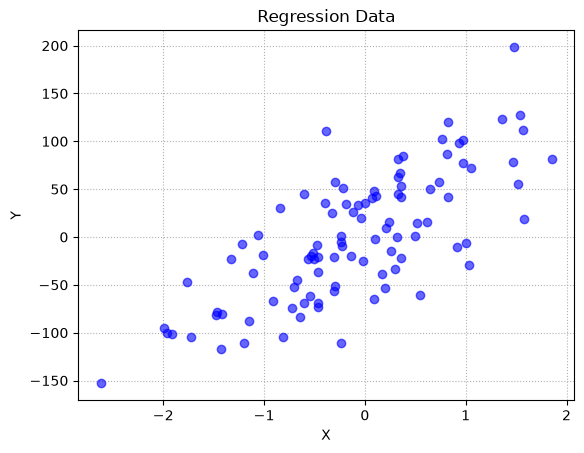

In [9]:
import matplotlib.pyplot as plt

plt.plot(X_reg, y_reg, 'o', color='blue', alpha=0.6)
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(ls=":")
plt.title('Regression Data')
plt.show()

In [10]:
# 3. Clustering dataset with 3 distinct centers
X_blobs, y_blobs = make_blobs(
    n_samples=200, 
    centers=3, 
    n_features=2, 
    random_state=42
)

# 4. Non-linear 2D moons
X_moons, y_moons = make_moons(n_samples=100, noise=0.1, random_state=42)

In [13]:
X_moons[:10,:]

array([[ 1.58202308, -0.44581483],
       [ 0.0660451 ,  0.4392075 ],
       [ 0.73663111, -0.39896339],
       [-1.05692838,  0.2424558 ],
       [-0.80216162,  0.20271838],
       [-0.70641308,  0.77076218],
       [ 0.2053884 ,  0.81875305],
       [ 1.37804958, -0.44658032],
       [ 0.8481931 ,  0.67172277],
       [ 0.92202981, -0.08438964]])

In [14]:
y_moons[:10]

array([1, 1, 1, 0, 0, 0, 0, 1, 0, 0])

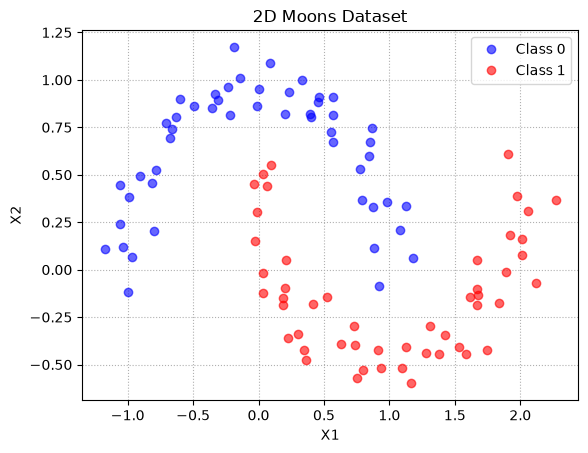

In [11]:
plt.plot(X_moons[y_moons == 0, 0], X_moons[y_moons == 0, 1], 'o', label='Class 0', color='blue', alpha=0.6)
plt.plot(X_moons[y_moons == 1, 0], X_moons[y_moons == 1, 1], 'o', label='Class 1', color='red', alpha=0.6)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('2D Moons Dataset')
plt.legend()
plt.grid(ls=":")
plt.show()